<a href="https://colab.research.google.com/github/bforoura/DBMS/blob/master/Module6_ChromaDB/vector_queries.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Vector Queries vs. SQL Queries**

* In traditional relational database management systems, a connection is typically established via a server URI pointing to a dedicated database daemon such as MySQL, PostgreSQL, or SQL Server.

* But, embedded **vector databases like ChromaDB** can operate entirely **in-memory** (**EphemeralClient**) or persist directly to local disk storage (**PersistentClient**).

* This allows vector stores to run locally within a Python script or a Google Colab notebook without requiring external server setup or configuration.

In [1]:
# Install ChromaDB in the Colab environment
!pip install -q chromadb

import chromadb

# Initialize an in-memory Chroma client for this session
client = chromadb.Client()

print("ChromaDB Client initialized successfully.")
print("Current Client Type:", type(client))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
t

# **Loading a Movies Dataset**

* In **data engineering and vector database applications**, datasets rarely arrive as manually typed lists. Instead, they are ingested programmatically from external repositories or cloud stores.

* To keep our Google Colab notebook entirely self-contained, we will use the **Hugging Face** datasets library.

* Let's load a verified corpus of real-world movie reviews (**rotten_tomatoes**) and programmatically slice the first 100 records.

* Each record pairs an unstructured text snippet (**the review text**) with structured binary metadata (**sentiment label: positive or negative**).


In [6]:
# Install the Hugging Face datasets library quietly
!pip install -q datasets

from datasets import load_dataset

# Load using the namespaced path on Hugging Face
raw_dataset = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train[:100]")

# Explicitly list-comprehend the documents to guarantee equal lengths
review_ids = [f"review_{i}" for i in range(len(raw_dataset))]
documents = [item for item in raw_dataset["text"]]
metadatas = [
    {"sentiment": "positive" if item["label"] == 1 else "negative", "source": "rotten_tomatoes"}
    for item in raw_dataset
]

# Ingest into our ChromaDB collection
collection.add(
    ids=review_ids,
    documents=documents,
    metadatas=metadatas
)

print(f"Successfully loaded and ingested {collection.count()} real movie reviews into ChromaDB.")

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:02<00:00, 30.2MiB/s]


Successfully loaded and ingested 100 real movie reviews into ChromaDB.


# **Executing Semantic Similarity Queries**


* In a **traditional relational database**, searching text fields requires **rigid pattern matching** using SQL operators like LIKE '%brilliant%' or full-text search indexes that look for **exact keyword overlaps**.

* If a **review** expresses the same sentiment using entirely different vocabulary; e.g., "**an absolute triumph of cinematic art**", an exact-match query will fail to find it.

* A **vector database** queries evaluate **semantic proximity**.

* When you pass a natural language query string to **collection.query()**, ChromaDB automatically passes that text through the **embedding model** to **generate a query vector**.

* It then computes the **geometric distance** such as **cosine distance** across all stored review vectors to find the nearest neighbors in the latent space, returning **results ranked by conceptual similarity** rather than keyword matching.

In [7]:
# Define a natural language semantic query string
query_string = "a brilliantly acted and emotionally powerful masterpiece"

# Query the collection for the top 3 most semantically similar reviews
results = collection.query(
    query_texts=[query_string],
    n_results=3,
    include=["documents", "metadatas", "distances"]
)

# Inspect the retrieved results, distances, and metadata
print(f"Query Text: '{query_string}'\n" + "-" * 60)
for i in range(len(results['ids'][0])):
    doc_id = results['ids'][0][i]
    doc_text = results['documents'][0][i]
    metadata = results['metadatas'][0][i]
    distance = results['distances'][0][i]

    print(f"Rank {i+1} | ID: {doc_id} | Distance Score: {distance:.4f}")
    print(f"Sentiment: {metadata['sentiment'].upper()}")
    print(f"Review Text: {doc_text}\n")

Query Text: 'a brilliantly acted and emotionally powerful masterpiece'
------------------------------------------------------------
Rank 1 | ID: review_17 | Distance Score: 0.7583
Sentiment: POSITIVE
Review Text: a masterpiece four years in the making .

Rank 2 | ID: review_31 | Distance Score: 0.8553
Sentiment: POSITIVE
Review Text: a masterful film from a master filmmaker , unique in its deceptive grimness , compelling in its fatalist worldview .

Rank 3 | ID: review_73 | Distance Score: 0.9013
Sentiment: POSITIVE
Review Text: this delicately observed story , deeply felt and masterfully stylized , is a triumph for its maverick director .



# **Combining Semantic Search with Relational Metadata Filtering**

* In a traditional relational database, **filtering** records based on specific attributes is handled using the **WHERE** clause:
    * **WHERE sentiment = 'positive' AND year >= 2020.**

* **Pure vector search** retrieves results solely based on **semantic proximity** across the entire dataset, which can **sometimes surface items that match the concept but violate business rules or categorical constraints**.

* To deal with this, vector databases support **Hybrid Retrieval or Metadata Filtering**.

* This allows use to **apply strict, deterministic relational filters** such as the SQL equivalent of WHERE directly inside the vector search operation.

* The database evaluates the metadata predicate first or in tandem with the vector index, ensuring that similarity ranking is restricted only to records that satisfy your exact categorical criteria.


In [8]:
# Define a semantic query string
query_string = "an engaging and well-crafted story"

# Execute a hybrid query combining semantic search with a SQL-like metadata filter
filtered_results = collection.query(
    query_texts=[query_string],
    n_results=3,
    where={"sentiment": "positive"},
    include=["documents", "metadatas", "distances"]
)

# Inspect the filtered results
print(f"Query Text: '{query_string}' | Filter: sentiment == 'positive'\n" + "-" * 60)
for i in range(len(filtered_results['ids'][0])):
    doc_id = filtered_results['ids'][0][i]
    doc_text = filtered_results['documents'][0][i]
    metadata = filtered_results['metadatas'][0][i]
    distance = filtered_results['distances'][0][i]

    print(f"Rank {i+1} | ID: {doc_id} | Distance Score: {distance:.4f}")
    print(f"Sentiment: {metadata['sentiment'].upper()}")
    print(f"Review Text: {doc_text}\n")

Query Text: 'an engaging and well-crafted story' | Filter: sentiment == 'positive'
------------------------------------------------------------
Rank 1 | ID: review_83 | Distance Score: 0.9593
Sentiment: POSITIVE
Review Text: an imaginative comedy/thriller .

Rank 2 | ID: review_73 | Distance Score: 1.0009
Sentiment: POSITIVE
Review Text: this delicately observed story , deeply felt and masterfully stylized , is a triumph for its maverick director .

Rank 3 | ID: review_20 | Distance Score: 1.0956
Sentiment: POSITIVE
Review Text: a thoughtful , provocative , insistently humanizing film .



# **Understanding the Hybrid Query Output**

* **Deterministic Filtering** (Sentiment: POSITIVE):
   * Just like a SQL WHERE clause, the where={"sentiment": "positive"} filter acts as a hard constraint.
   * This strictly eliminates any records that do not match the metadata attribute before or during similarity evaluation.

* **Geometric Ranking** (Rank & Distance Score):
  * Unlike SQL queries ordered by explicit column values, vector results are ranked by geometric proximity in high-dimensional space **analogous to ORDER BY distance ASC LIMIT 3**.
  
  * Lower distance scores indicate closer conceptual alignment **bold text** between the query text and the stored document.

* **Semantic Matching** (Review Text):
  * Within the filtered subset, records are retrieved based on conceptual meaning rather than exact keyword overlap.
  
  * This extracts reviews that express the same idea even if they use different vocabulary.

# **Modifying and Deleting Records (Vector CRUD Operations)**

* In a traditional relational database, modifying data or removing rows is handled via SQL **UPDATE and DELETE** statements targeting specific table columns and row conditions.

* In vector databases, **CRUD** operations are **anchored** directly to the **unique record ID.**

* **Updates (upsert)**:
  * Because vector **embeddings are derived directly from unstructured text**, modifying a record's text means the **database must re-compute its high-dimensional vector**.
  
  * ChromaDB provides an **upsert()** method which acts as an "**insert-or-update**" operation—if the ID already exists, it replaces the old document, updates its metadata, and generates a **fresh embedding**.

* **Deletions (delete)**:
  * Removing a record requires its unique ID, which purges the document text, its structured metadata, and its vector from the index simultaneously.
  
  * This is analogous to a SQL **DELETE FROM table WHERE id = ...**

In [9]:
# 1. Update an existing record using upsert
# If 'review_0' exists, ChromaDB replaces its document, metadata, and re-embeds the text.
collection.upsert(
    ids=["review_0"],
    documents=["An absolute cinematic masterpiece with breathtaking direction and stellar performances."],
    metadatas=[{"sentiment": "positive", "source": "rotten_tomatoes"}]
)

print("Updated review_0 successfully.")

# 2. Delete a record by ID
collection.delete(
    ids=["review_99"]
)

print(f"Deleted review_99. Total records remaining in collection: {collection.count()}")

Updated review_0 successfully.
Deleted review_99. Total records remaining in collection: 99


# **Advanced Vector Search: Grouping and Result Diversification**




* In SQL databases, **GROUP BY **is a native, engine-level operation optimized for aggregation.

* In open-source local vector databases such as ChromaDB's local client, native **grouping are often unavailable or reserved for enterprise cloud editions.**

* To achieve categorical organization in a local environment, developers use an application-layer pattern:
  *  first execute a standard semantic query to retrieve the top N nearest neighbors
  * then use Python's standard library (**collections.defaultdict**) to  bucket and organize the results by metadata attributes.

* This bridges the gap between probabilistic vector similarity and deterministic data categorization.  

In [12]:
from collections import defaultdict

# Query a broad set of results from our local collection
results = collection.query(
    query_texts=["masterpiece movie review"],
    n_results=10,
    include=["documents", "metadatas", "distances"]
)

# Group and organize results locally by sentiment metadata
grouped_reviews = defaultdict(list)
for doc_id, doc_text, meta, dist in zip(
    results['ids'][0],
    results['documents'][0],
    results['metadatas'][0],
    results['distances'][0]
):
    sentiment = meta.get('sentiment', 'unknown')
    grouped_reviews[sentiment].append({
        "id": doc_id,
        "text": doc_text,
        "distance": dist
    })

# Inspect the grouped output
for sentiment, items in grouped_reviews.items():
    print(f"Sentiment Category: {sentiment.upper()} (Total: {len(items)} items)")
    for item in items:
        print(f"  - ID: {item['id']} | Distance: {item['distance']:.4f}")
    print("-" * 50)

Sentiment Category: POSITIVE (Total: 10 items)
  - ID: review_0 | Distance: 0.7477
  - ID: review_31 | Distance: 0.8499
  - ID: review_17 | Distance: 0.8957
  - ID: review_34 | Distance: 1.0208
  - ID: review_10 | Distance: 1.0654
  - ID: review_80 | Distance: 1.0871
  - ID: review_60 | Distance: 1.1239
  - ID: review_73 | Distance: 1.1313
  - ID: review_21 | Distance: 1.1448
  - ID: review_76 | Distance: 1.1510
--------------------------------------------------


# **Explanation of the Grouped Query Output**

* **Category Header -- Sentiment Category: POSITIVE (Total: 10 items)**:
  * We grouped the search results based on the metadata key (sentiment: "positive").
  
  * Out of the broad query results, 10 records matched this specific **categorical bucket**.

* **Record Identifier (ID: review_0)**:
 * The unique string key assigned to each individual document during ingestion. * This allows us to trace back exact rows in the dataset.

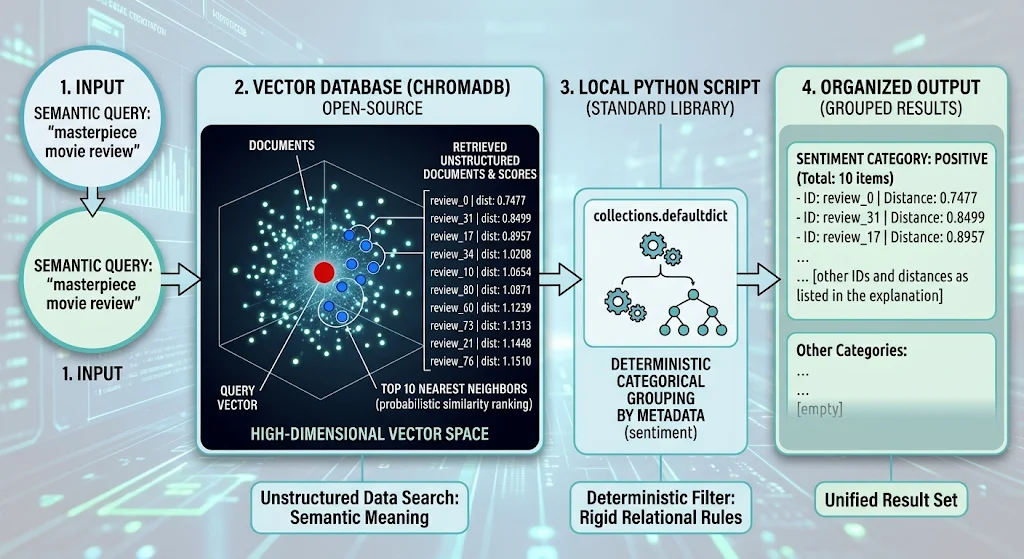